### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 7

### Delivery Drone Q-Learning

### Name: Yashvanth Karunakaran (23BAI1589)

Notebook Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-7.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-7.ipynb)

### AIM:
To Implement a python program using deep Q-learning to learn CartPole

### Problem:
CartPole is a control problem where a pole is attached to a cart via an unactuated joint. The cart can move left or right. Goal is to Balance the pole by moving the cart. Reward: +1 for each timestep the pole stays upright. Max Episode Length: 500 steps (v1)

### Creating CartPole environment
[https://gymnasium.farama.org/environments/classic_control/cart_pole/](https://gymnasium.farama.org/environments/classic_control/cart_pole/)


In [1]:
import gymnasium as gym

env = gym.make("CartPole-v1")

### Action Space

In [2]:
print(env.action_space)
print("0: Push cart to the left, 1: Push cart to the right")

Discrete(2)
0: Push cart to the left, 1: Push cart to the right


### Observation Space

In [3]:
import pandas as pd

columns = ["Cart Position", "Cart Velocity", "Pole Angle", "Pole Angular Velocity"]

df = pd.DataFrame({"Observation": columns, "Min": env.observation_space.low, "Max": env.observation_space.high})

print(df)

             Observation       Min       Max
0          Cart Position -4.800000  4.800000
1          Cart Velocity      -inf       inf
2             Pole Angle -0.418879  0.418879
3  Pole Angular Velocity      -inf       inf


### Agent Evalution Function

In [4]:
import numpy as np

def evaluate_agent(env, agent=None, num_episodes=10, deterministic=True, render=False):
    """
    Evaluate an agent (or random policy if agent=None) over multiple episodes.
    
    Args:
        env: Gymnasium environment
        agent: Trained agent (if None, uses random actions)
        num_episodes: Number of episodes to run
        deterministic: Whether to use deterministic policy
        render: Whether to render the environment
        
    Returns:
        rewards: List of episode rewards
        episode_lengths: List of episode lengths
    """
    rewards = []
    episode_lengths = []
    
    for episode in range(num_episodes):
        obs, info = env.reset()
        episode_reward = 0
        episode_length = 0
        done = False
        
        while not done:
            if agent is None:
                action = env.action_space.sample()
            else:
                action, _states = agent.predict(obs, deterministic=deterministic)
            
            obs, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            episode_length += 1
            done = terminated or truncated
        
        rewards.append(episode_reward)
        episode_lengths.append(episode_length)
    
    return np.array(rewards), np.array(episode_lengths)

### Random Agent Policy
Sampling Random actions from Environment Space

In [5]:
random_rewards, random_lengths = evaluate_agent(env, agent=None, num_episodes=20, deterministic=True, render=False)

print(f"Random Agent Performance (20 episodes):")
print(f"Mean Reward: {random_rewards.mean()}")
print(f"Std Dev: {random_rewards.std()}")
print(f"Min Reward: {random_rewards.min()}")
print(f"Max Reward: {random_rewards.max()}")
print(f"Mean Episode Length: {random_lengths.mean()}")
print(f"Std Dev: {random_lengths.std()}")

Random Agent Performance (20 episodes):
Mean Reward: 16.95
Std Dev: 6.785830826066915
Min Reward: 8.0
Max Reward: 38.0
Mean Episode Length: 16.95
Std Dev: 6.785830826066915


### DQN Model
MlpPolicy - 	Neural network policy<br>
learning_rate - 	Neural-network learning rate<br>
buffer_size - 	Replay-buffer capacity<br>
learning_starts - 	Start training after this many experiences<br>
batch_size - 	Number of experiences per update<br>
gamma - 	Discount factor<br>
train_freq - 	How often training occurs<br>
target_update_interval - 	Target-network update frequency<br>
exploration_initial_eps - 	Initial epsilon<br>
exploration_final_eps - 	Final epsilon<br>

In [6]:
from stable_baselines3 import DQN

model = DQN(policy = "MlpPolicy", env = env, learning_rate = 0.001, buffer_size = 50000, learning_starts = 1000, batch_size = 64, gamma = 0.99, train_freq = 4, target_update_interval = 1000, exploration_fraction = 0.5, exploration_final_eps = 0.05, exploration_initial_eps = 1.0, verbose = 1)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


### Train the DQN agent

In [7]:
model.learn(total_timesteps=100000, log_interval=1000)

----------------------------------
| rollout/            |          |
|    ep_len_mean      | 33.6     |
|    ep_rew_mean      | 33.6     |
|    exploration_rate | 0.397    |
| time/               |          |
|    episodes         | 1000     |
|    fps              | 1466     |
|    time_elapsed     | 21       |
|    total_timesteps  | 31736    |
| train/              |          |
|    learning_rate    | 0.001    |
|    loss             | 0.0367   |
|    n_updates        | 7683     |
----------------------------------


### Save the trained model and replay buffer

In [8]:
model.save("cartpole_dqn")
model.save_replay_buffer("cartpole_dqn_replay_buffer")

### Load the trained model

In [9]:
model = DQN.load("cartpole_dqn", env = env)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


### Test the trained agent

In [10]:
trained_rewards, trained_lengths = evaluate_agent(env, agent=model, num_episodes=20, deterministic=True)

print(f"Trained DQN Agent Performance (20 episodes):")
print(f"Mean Reward: {trained_rewards.mean()}")
print(f"Std Dev: {trained_rewards.std()}")
print(f"Min Reward: {trained_rewards.min()}")
print(f"Max Reward: {trained_rewards.max()}")
print(f"Mean Episode Length: {trained_lengths.mean()}")
print(f"Std Dev: {trained_lengths.std()}")

Trained DQN Agent Performance (20 episodes):
Mean Reward: 91.35
Std Dev: 3.1666228067138023
Min Reward: 87.0
Max Reward: 97.0
Mean Episode Length: 91.35
Std Dev: 3.1666228067138023


### Evaluate over multiple episodes

In [11]:
num_episodes = 10
total_rewards = []

for episode in range(num_episodes):
    obs, info = env.reset()
    reward_sum = 0
    
    while True:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        reward_sum += reward
        
        if terminated or truncated:
            break
            
    total_rewards.append(reward_sum)
    print(f"Episode {episode + 1}: Reward = {reward_sum}")

print(f"Average Reward: {sum(total_rewards) / len(total_rewards)}")

Episode 1: Reward = 91.0
Episode 2: Reward = 85.0
Episode 3: Reward = 89.0
Episode 4: Reward = 88.0
Episode 5: Reward = 87.0
Episode 6: Reward = 89.0
Episode 7: Reward = 89.0
Episode 8: Reward = 90.0
Episode 9: Reward = 89.0
Episode 10: Reward = 87.0
Average Reward: 88.4


### Cumulative Reward Comparison over Random Agent and Trained DQN

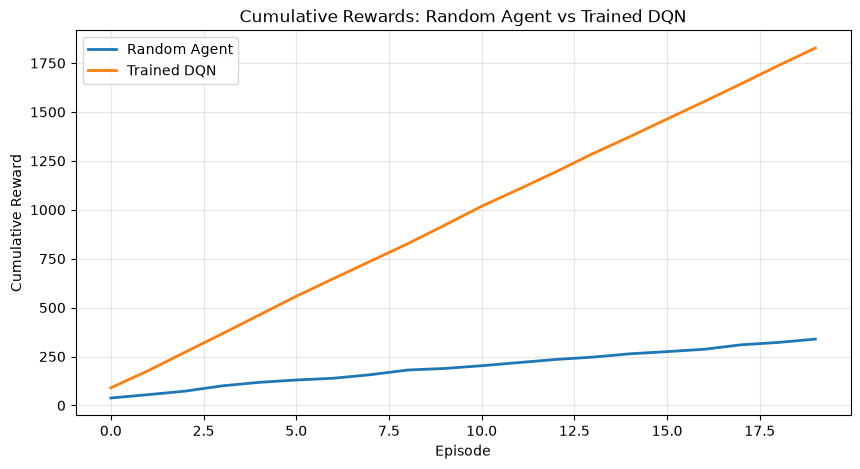

In [12]:
import matplotlib.pyplot as plt

random_cumsum = np.cumsum(random_rewards)
trained_cumsum = np.cumsum(trained_rewards)

plt.figure(figsize=(10, 5))

plt.plot(random_cumsum, label="Random Agent", linewidth=2)

plt.plot(trained_cumsum, label="Trained DQN", linewidth=2)

plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Rewards: Random Agent vs Trained DQN")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Reward Comparison Per Episode over Random Agent and Trained DQN

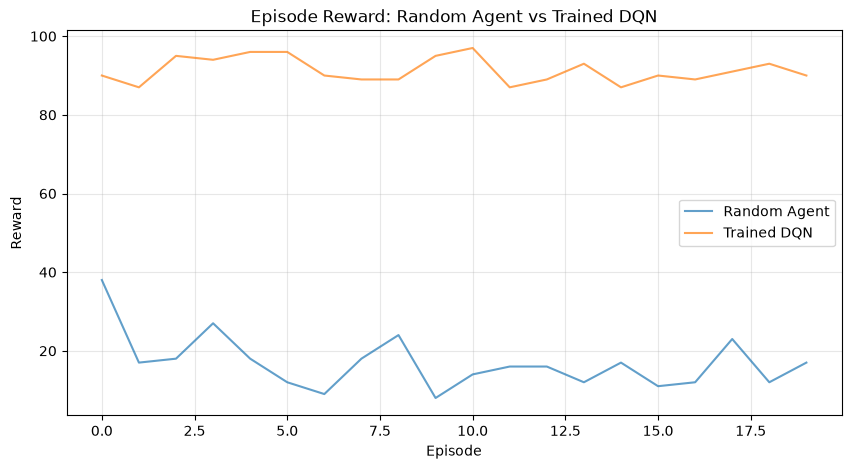

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(random_rewards, label="Random Agent", alpha=0.7)

plt.plot(trained_rewards, label="Trained DQN", alpha=0.7)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Episode Reward: Random Agent vs Trained DQN")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Conclusion:
In this assignment, Deep Q-Learning (DQN) was successfully used to train an agent to play the CartPole environment. Performance comparison between the random agent and the trained DQN agent shows that the trained agent achieves much higher rewards and a better success rate. This demonstrates that DQN can effectively learn a suitable policy for the CartPole problem.